# Frequent Word Analysis — Twain vs. Reference Corpora

**Purpose:** Examines the frequency and distribution of four coordinating and connective words (and, then, so, and but) in Twain's corpus and compares their usage against both reference corpora. The analysis investigates corpus-level differences, variation across individual novels, and the stylistic significance of connective usage.

**Method:** Raw frequency counting + relative frequency (per 10k); log-likelihood (G²) tests to assess differences between corpora. Additional per-book comparisons and passage extraction support close reading.

**Inputs:** All three corpora (Twain, child, adult).

**Output:** Comparative frequency tables; log-likelihood results; per-book frequency tables; bar charts; selected passages for close reading.

**Used in:** Chapter 4, coordination patterns and stylistic variation in Twain's fiction.

**Note:** This notebook went through several iterations (visible in the repeated visualization cells). The final versions of revised analyses supersede earlier versions. Earlier versions are retained for audit purposes.


In [4]:
import pandas as pd

target_words = ["and", "then", "so", "but"]

rows = []

for word in target_words:
    rows.append({
        "Word": word,
        "Twain count": twain_freq[word],
        "Twain per 10k": twain_freq[word] / N_twain * 10000,
        "Child count": child_freq[word],
        "Child per 10k": child_freq[word] / N_child * 10000,
        "Adult count": adult_freq[word],
        "Adult per 10k": adult_freq[word] / N_adult * 10000,
    })

df_connectives = pd.DataFrame(rows)

print(df_connectives.round(3).to_string(index=False))

Word  Twain count  Twain per 10k  Child count  Child per 10k  Adult count  Adult per 10k
 and        12491        503.154        21404        381.489        75110        284.893
then         1214         48.902         1407         25.077         5311         20.145
  so         1628         65.578         3266         58.211         9978         37.847
 but         2157         86.887         3826         68.192        17538         66.522


In [7]:
import math

def g2_test(k1, n1, k2, n2):
    observed = [
        [k1, n1 - k1],
        [k2, n2 - k2]
    ]

    row_totals = [n1, n2]
    column_totals = [k1 + k2, n1 + n2 - k1 - k2]
    grand_total = n1 + n2

    g2 = 0.0

    for i in range(2):
        for j in range(2):
            count = observed[i][j]
            expected = (
                row_totals[i] * column_totals[j] / grand_total
            )

            if count > 0:
                g2 += 2 * count * math.log(count / expected)

    # Chi-square approximation, one degree of freedom.
    p = math.erfc(math.sqrt(max(g2, 0) / 2))
    return g2, p


test_rows = []

for word in target_words:
    for label, reference_freq, reference_total in [
        ("Child", child_freq, N_child),
        ("Adult", adult_freq, N_adult),
    ]:
        g2, p = g2_test(
            twain_freq[word], N_twain,
            reference_freq[word], reference_total
        )

        test_rows.append({
            "Word": word,
            "Comparison": f"Twain vs {label}",
            "G²": round(g2, 3),
            "p": f"{p:.3e}" if p > 0 else "<1e-300",
            "Twain rate": (
                "Higher"
                if twain_freq[word] / N_twain
                > reference_freq[word] / reference_total
                else ("Lower" if twain_freq[word] / N_twain < reference_freq[word] / reference_total else "Equal")
            )
        })

df_connective_tests = pd.DataFrame(test_rows)
print(df_connective_tests.to_string(index=False))

Word     Comparison       G²          p Twain rate
 and Twain vs Child  614.951 9.375e-136     Higher
 and Twain vs Adult 3135.040    <1e-300     Higher
then Twain vs Child  281.919  2.866e-63     Higher
then Twain vs Adult  643.083 7.136e-142     Higher
  so Twain vs Child   15.312  9.114e-05     Higher
  so Twain vs Adult  372.160  6.336e-83     Higher
 but Twain vs Child   79.608  4.565e-19     Higher
 but Twain vs Adult  128.774  7.599e-30     Higher


In [9]:
# Save in a separate results folder; source texts are only read.
OUTPUT_DIR = BASE_PATH / "coordination_narrative_results"
OUTPUT_DIR.mkdir(exist_ok=True)
df_book_tokens.to_csv(OUTPUT_DIR / "per_book_tokens.csv", index=False)
df_connectives.to_csv(OUTPUT_DIR / "connective_frequencies.csv", index=False)
df_connective_tests.to_csv(OUTPUT_DIR / "connective_g2_tests.csv", index=False)
print("Results saved to:", OUTPUT_DIR)


Results saved to: /Users/manalaltammami/Desktop/twain_child_corpus/coordination_narrative_results


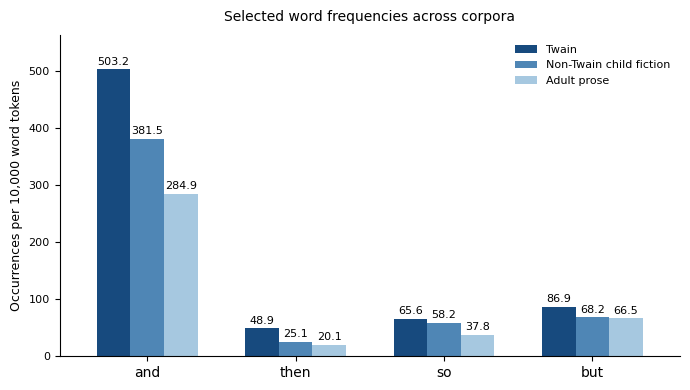

PNG saved to: /Users/manalaltammami/Desktop/twain_child_corpus/coordination_narrative_results/connectives_narrative.png
PDF saved to: /Users/manalaltammami/Desktop/twain_child_corpus/coordination_narrative_results/connectives_narrative.pdf


In [13]:

import matplotlib.pyplot as plt
from pathlib import Path

# Use the calculated results directly.
chart_data = df_connectives.set_index("Word")[
    ["Twain per 10k", "Child per 10k", "Adult per 10k"]
].rename(columns={
    "Twain per 10k": "Twain",
    "Child per 10k": "Non-Twain child fiction",
    "Adult per 10k": "Adult prose"
})

# Three coordinated shades of blue
colors = [
    "#174A7E",  # Twain: dark blue
    "#4F86B5",  # Child fiction: medium blue
    "#A6C8E0"   # Adult prose: light blue
]

# Smaller figure: previously (10, 6)
ax = chart_data.plot.bar(
    figsize=(7, 4),
    color=colors,
    width=0.68,
    rot=0
)

# Axis labels
ax.set_xlabel("")
ax.set_ylabel(
    "Occurrences per 10,000 word tokens",
    fontsize=9
)

# Smaller title
ax.set_title(
    "Selected word frequencies across corpora",
    fontsize=10,
    pad=10
)

# Readable tick labels
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=8)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Compact legend
ax.legend(
    frameon=False,
    fontsize=8,
    loc="upper right"
)

# Numerical labels above bars
for bars in ax.containers:
    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=2,
        fontsize=8
    )

# Leave space for numerical labels
ax.margins(y=0.12)

plt.tight_layout()

# Save PNG and PDF for Overleaf
output_path = OUTPUT_DIR / "connectives_narrative.png"
pdf_path = OUTPUT_DIR / "connectives_narrative.pdf"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print("PNG saved to:", output_path)
print("PDF saved to:", pdf_path)


In [31]:
# Per-novel connective frequencies for the three Twain novels.
# Uses the same files, tokenizer, and verified totals as Step 1.

novel_names = {
    "Tom_Sawyer_narrative.txt": "Tom Sawyer",
    "Huckleberry_Finn_narrative.txt": "Huckleberry Finn",
    "Prince_and_the_Pauper_narrative.txt": "The Prince and the Pauper",
}

novel_rows = []

for filename in twain_files:
    text = (BASE_PATH / filename).read_text(encoding="utf-8")
    tokens = tokenize(text)
    total = len(tokens)

    if total != EXPECTED_BOOK_TOKENS[filename]:
        raise ValueError(f"Unexpected token total for {filename}")

    freq = Counter(tokens)

    for word in ["and", "then", "so", "but"]:
        novel_rows.append({
            "Novel": novel_names[filename],
            "Tokens": total,
            "Word": word,
            "Count": freq[word],
            "Per 10,000": freq[word] / total * 10000,
        })

df_novel_connectives = pd.DataFrame(novel_rows)

print(
    df_novel_connectives.round(3).to_string(index=False)
)

                    Novel  Tokens Word  Count  Per 10,000
               Tom Sawyer   70518  and   3087     437.761
               Tom Sawyer   70518 then    307      43.535
               Tom Sawyer   70518   so    355      50.342
               Tom Sawyer   70518  but    580      82.249
         Huckleberry Finn  110729  and   6264     565.705
         Huckleberry Finn  110729 then    599      54.096
         Huckleberry Finn  110729   so    960      86.698
         Huckleberry Finn  110729  but   1035      93.471
The Prince and the Pauper   67007  and   3140     468.608
The Prince and the Pauper   67007 then    308      45.965
The Prince and the Pauper   67007   so    313      46.712
The Prince and the Pauper   67007  but    542      80.887


In [33]:
import random

passage_rows = []

for filename in twain_files:
    text = (BASE_PATH / filename).read_text(encoding="utf-8")
    paragraphs = re.split(r"\n\s*\n", text.strip())
    candidates = []

    for paragraph_number, paragraph in enumerate(paragraphs, start=1):
        tokens = tokenize(paragraph)
        and_count = tokens.count("and")

        # A consistent rule for finding manageable passages.
        if 40 <= len(tokens) <= 200 and and_count >= 4:
            candidates.append({
                "Novel": novel_names[filename],
                "Paragraph": paragraph_number,
                "Tokens": len(tokens),
                "And count": and_count,
                "Passage": paragraph.strip(),
            })

    print(f"\n=== {novel_names[filename]} ===")
    print(f"Qualifying paragraphs: {len(candidates)}")

    rng = random.Random(42)
    selected = rng.sample(candidates, min(3, len(candidates)))

    for row in sorted(selected, key=lambda item: item["Paragraph"]):
        passage_rows.append(row)
        print(
            f"\nParagraph {row['Paragraph']} | "
            f"{row['Tokens']} tokens | "
            f"{row['And count']} occurrences of 'and'"
        )
        print(row["Passage"])

df_and_passages = pd.DataFrame(passage_rows)


=== Tom Sawyer ===
Qualifying paragraphs: 237

Paragraph 104 | 97 tokens | 10 occurrences of 'and'
The new boy took two broad coppers out of his pocket and held them out
with derision. Tom struck them to the ground. In an instant both boys
were rolling and tumbling in the dirt, gripped together like cats; and
for the space of a minute they tugged and tore at each other’s hair and
clothes, punched and scratched each other’s nose, and covered themselves
with dust and glory. Presently the confusion took form, and through the
fog of battle Tom appeared, seated astride the new boy, and pounding him
with his fists. “Holler ’nuff!” said he.

Paragraph 206 | 77 tokens | 7 occurrences of 'and'
Mary gave him a tin basin of water and a piece of soap, and he went
outside the door and set the basin on a little bench there; then he
dipped the soap in the water and laid it down; turned up his sleeves;
poured out the water on the ground, gently, and then entered the kitchen
and began to wipe his face

In [35]:
# Per-book frequencies in both comparison corpora.
# Uses the same narrative files and tokenizer as the main analysis.

comparison_rows = []

for corpus_label, file_list in [
    ("Non-Twain child fiction", child_files),
    ("Adult fiction", adult_files),
]:
    for filename in file_list:
        text = (BASE_PATH / filename).read_text(encoding="utf-8")
        tokens = tokenize(text)
        total = len(tokens)

        if total != EXPECTED_BOOK_TOKENS[filename]:
            raise ValueError(
                f"Unexpected token total for {filename}"
            )

        freq = Counter(tokens)

        row = {
            "Corpus": corpus_label,
            "Text": filename.removesuffix("_narrative.txt").replace("_", " "),
            "Tokens": total,
        }

        for word in ["and", "then", "so", "but"]:
            row[f"{word} count"] = freq[word]
            row[f"{word} per 10k"] = freq[word] / total * 10000

        comparison_rows.append(row)

df_comparison_books = pd.DataFrame(comparison_rows)

# Display rates; preserve exact counts in the saved CSV.
rate_columns = [
    "Text", "Tokens",
    "and per 10k", "then per 10k",
    "so per 10k", "but per 10k",
]

for label in ["Non-Twain child fiction", "Adult fiction"]:
    print(f"\n=== {label.upper()} ===\n")
    print(
        df_comparison_books.loc[
            df_comparison_books["Corpus"] == label,
            rate_columns,
        ].round(3).to_string(index=False)
    )

results_folder = BASE_PATH / "coordination_narrative_results"
results_folder.mkdir(exist_ok=True)

output_file = results_folder / "comparison_per_book_connectives.csv"
df_comparison_books.to_csv(output_file, index=False)

print("\nSaved:", output_file)


=== NON-TWAIN CHILD FICTION ===

                  Text  Tokens  and per 10k  then per 10k  so per 10k  but per 10k
           Ragged Dick   47722      245.379        17.392      39.814       73.970
          Little Women  185825      432.342        19.965      60.971       78.784
 An Old Fashioned Girl  101818      405.331        21.018      70.714       75.036
            Toby Tyler   50233      293.034        38.222      52.555       56.138
   Five Little Peppers   69400      352.594        46.254      63.833       44.669
     Hoosier Schoolboy   36080      343.404        27.716      34.645       81.208
Little Lord Fauntleroy   58627      432.906        18.080      59.188       47.248
    The Story of Patsy   11359      331.015        17.607      38.736       73.070

=== ADULT FICTION ===

                Text  Tokens  and per 10k  then per 10k  so per 10k  but per 10k
        Silas Lapham  129245      299.277        27.158      37.835       79.771
    Ministers Charge  115995     

In [37]:
import random

comparison_passages = []
sampling_summary = []

for corpus_label, file_list in [
    ("Non-Twain child fiction", child_files),
    ("Adult fiction", adult_files),
]:
    for filename in file_list:
        text = (BASE_PATH / filename).read_text(encoding="utf-8")
        paragraphs = re.split(r"\n\s*\n", text.strip())
        candidates = []

        for number, paragraph in enumerate(paragraphs, start=1):
            tokens = tokenize(paragraph)
            and_count = tokens.count("and")

            # Same selection rule used for the Twain passages.
            if 40 <= len(tokens) <= 200 and and_count >= 4:
                candidates.append({
                    "Corpus": corpus_label,
                    "File": filename,
                    "Paragraph": number,
                    "Tokens": len(tokens),
                    "And count": and_count,
                    "Passage": paragraph.strip(),
                })

        rng = random.Random(42)
        selected = rng.sample(candidates, min(3, len(candidates)))

        comparison_passages.extend(
            sorted(selected, key=lambda row: row["Paragraph"])
        )

        sampling_summary.append({
            "File": filename,
            "Qualifying paragraphs": len(candidates),
            "Selected paragraphs": len(selected),
        })

df_comparison_passages = pd.DataFrame(comparison_passages)
df_sampling_summary = pd.DataFrame(sampling_summary)

results_folder = BASE_PATH / "coordination_narrative_results"
results_folder.mkdir(exist_ok=True)

df_comparison_passages.to_csv(
    results_folder / "comparison_and_passages.csv", index=False
)
df_sampling_summary.to_csv(
    results_folder / "comparison_passage_sampling.csv", index=False
)

print(df_sampling_summary.to_string(index=False))

print("\n=== DEEPHAVEN: SELECTED PASSAGES ===")

for row in comparison_passages:
    if row["File"] == "Deephaven_narrative.txt":
        print(
            f"\nParagraph {row['Paragraph']} | "
            f"{row['Tokens']} tokens | "
            f"{row['And count']} occurrences of 'and'"
        )
        print(row["Passage"])

print("\nFiles saved in:", results_folder)

                                File  Qualifying paragraphs  Selected paragraphs
           Ragged_Dick_narrative.txt                     59                    3
          Little_Women_narrative.txt                    658                    3
 An_Old_Fashioned_Girl_narrative.txt                    309                    3
            Toby_Tyler_narrative.txt                     83                    3
   Five_Little_Peppers_narrative.txt                    134                    3
     Hoosier_Schoolboy_narrative.txt                     95                    3
Little_Lord_Fauntleroy_narrative.txt                    172                    3
    The_Story_of_Patsy_narrative.txt                     31                    3
          Silas_Lapham_narrative.txt                    242                    3
      Ministers_Charge_narrative.txt                    238                    3
   Hazard_New_Fortunes_narrative.txt                    230                    3
    Portrait_of_a_Lady_narra